In [28]:
import json
import random
import math
from urllib.request import Request, urlopen
import pandas as pd
import matplotlib.pyplot as plt

TEAM_ID = "TEAM_01"
API_URL = "https://bftrxasgtunepckchcoz.supabase.co/functions/v1/oracle"


def api(payload):
    req = Request(
        API_URL,
        data=json.dumps(payload).encode(),
        headers={
            "Content-Type": "application/json",
            "X-API-Key": API_KEY
        }
    )

    with urlopen(req, timeout=30) as response:
        return json.load(response)


spec = api({
    "action": "spec",
    "team_id": TEAM_ID
})

MODEL = spec["model"]
SPACE = spec["hyperparameters"]

print("Assigned Model:", MODEL)
print("\nHyperparameter Search Space:")

for name, values in SPACE.items():
    print(f"{name}: {values}")

Assigned Model: DecisionTreeRegressor

Hyperparameter Search Space:
splitter: ['best', 'random']
criterion: ['squared_error', 'friedman_mse']
max_depth: [2, 3, 4, 5, 6, 8, 10, None]
max_features: [0.4, 0.6, 0.8, 1]
min_samples_leaf: [1, 2, 4, 8]
min_samples_split: [2, 5, 10, 20]


In [15]:
def oracle_query(params):
    result = api({
        "action": "query",
        "team_id": TEAM_ID,
        "params": params
    })

    return float(result["loss"])

In [16]:
def random_configuration():
    params = {}

    for name, values in SPACE.items():
        params[name] = random.choice(values)

    return params


def configuration_key(params):
    return tuple(
        (name, params[name])
        for name in sorted(params.keys())
    )


def mutate_configuration(params):
    new_params = params.copy()

    parameter_names = list(SPACE.keys())

    number_of_changes = random.randint(
        1,
        max(1, len(parameter_names) // 2)
    )

    selected_parameters = random.sample(
        parameter_names,
        number_of_changes
    )

    for name in selected_parameters:

        possible_values = SPACE[name]

        if len(possible_values) > 1:

            current_value = new_params[name]

            alternatives = [
                value
                for value in possible_values
                if value != current_value
            ]

            new_params[name] = random.choice(alternatives)

    return new_params

In [17]:
MAX_CALLS = 30

history = []
visited = set()

best_params = None
best_loss = float("inf")

In [18]:
def evaluate(params):

    global best_params
    global best_loss

    key = configuration_key(params)

    if key in visited:
        return None

    visited.add(key)

    loss = oracle_query(params)

    history.append({
        "call": len(history) + 1,
        "params": params.copy(),
        "loss": loss
    })

    print(
        f"Call {len(history):02d} | "
        f"Loss: {loss:.6f}"
    )

    print("Parameters:", params)

    if loss < best_loss:

        best_loss = loss
        best_params = params.copy()

        print(">>> NEW BEST")

    print()

    return loss

In [19]:
while len(history) < MAX_CALLS:

    if best_params is None:

        candidate = random_configuration()

    else:

        if random.random() < 0.70:
            candidate = mutate_configuration(best_params)
        else:
            candidate = random_configuration()

    evaluate(candidate)

Call 01 | Loss: 17.855389
Parameters: {'splitter': 'best', 'criterion': 'squared_error', 'max_depth': 2, 'max_features': 0.8, 'min_samples_leaf': 8, 'min_samples_split': 10}
>>> NEW BEST

Call 02 | Loss: 17.855389
Parameters: {'splitter': 'best', 'criterion': 'squared_error', 'max_depth': 2, 'max_features': 0.8, 'min_samples_leaf': 4, 'min_samples_split': 5}

Call 03 | Loss: 7.498326
Parameters: {'splitter': 'best', 'criterion': 'squared_error', 'max_depth': 5, 'max_features': 0.8, 'min_samples_leaf': 8, 'min_samples_split': 10}
>>> NEW BEST

Call 04 | Loss: 11.220775
Parameters: {'splitter': 'random', 'criterion': 'friedman_mse', 'max_depth': 5, 'max_features': 0.8, 'min_samples_leaf': 8, 'min_samples_split': 10}

Call 05 | Loss: 10.665514
Parameters: {'splitter': 'best', 'criterion': 'squared_error', 'max_depth': 4, 'max_features': 0.8, 'min_samples_leaf': 8, 'min_samples_split': 20}

Call 06 | Loss: 17.855389
Parameters: {'splitter': 'best', 'criterion': 'friedman_mse', 'max_depth':

In [22]:
print("FINAL RESULT")
print("=" * 12)

print("\nBest Hyperparameters:")

for parameter, value in best_params.items():
    print(f"{parameter}: {value}")

print(f"\nBest Loss: {best_loss:.6f}")
print(f"Total Oracle Calls: {len(history)}")

FINAL RESULT

Best Hyperparameters:
splitter: best
criterion: friedman_mse
max_depth: 6
max_features: 1
min_samples_leaf: 8
min_samples_split: 20

Best Loss: 6.721072
Total Oracle Calls: 30


In [23]:
history_df = pd.DataFrame(history)

history_df["parameters"] = history_df["params"].apply(str)

result_df = history_df[
    ["call", "parameters", "loss"]
]

result_df

,call,parameters,loss
0,1,"{'splitter': 'best', 'criterion': 'squared_err...",17.855389
1,2,"{'splitter': 'best', 'criterion': 'squared_err...",17.855389
2,3,"{'splitter': 'best', 'criterion': 'squared_err...",7.498326
3,4,"{'splitter': 'random', 'criterion': 'friedman_...",11.220775
4,5,"{'splitter': 'best', 'criterion': 'squared_err...",10.665514
5,6,"{'splitter': 'best', 'criterion': 'friedman_ms...",17.855389
6,7,"{'splitter': 'random', 'criterion': 'squared_e...",11.220775
7,8,"{'splitter': 'best', 'criterion': 'squared_err...",8.471405
8,9,"{'splitter': 'best', 'criterion': 'friedman_ms...",7.498326
9,10,"{'splitter': 'best', 'criterion': 'friedman_ms...",10.025454


In [24]:
top_results = history_df.sort_values(
    by="loss"
).head(10)

for _, row in top_results.iterrows():

    print(f"Call: {row['call']}")
    print(f"Loss: {row['loss']:.6f}")
    print(f"Parameters: {row['params']}")
    print("-" * 60)

Call: 19
Loss: 6.721072
Parameters: {'splitter': 'best', 'criterion': 'friedman_mse', 'max_depth': 6, 'max_features': 1, 'min_samples_leaf': 8, 'min_samples_split': 20}
------------------------------------------------------------
Call: 29
Loss: 7.363104
Parameters: {'splitter': 'best', 'criterion': 'squared_error', 'max_depth': 6, 'max_features': 0.8, 'min_samples_leaf': 8, 'min_samples_split': 5}
------------------------------------------------------------
Call: 3
Loss: 7.498326
Parameters: {'splitter': 'best', 'criterion': 'squared_error', 'max_depth': 5, 'max_features': 0.8, 'min_samples_leaf': 8, 'min_samples_split': 10}
------------------------------------------------------------
Call: 9
Loss: 7.498326
Parameters: {'splitter': 'best', 'criterion': 'friedman_mse', 'max_depth': 5, 'max_features': 0.8, 'min_samples_leaf': 8, 'min_samples_split': 10}
------------------------------------------------------------
Call: 16
Loss: 8.288706
Parameters: {'splitter': 'best', 'criterion': 'frie

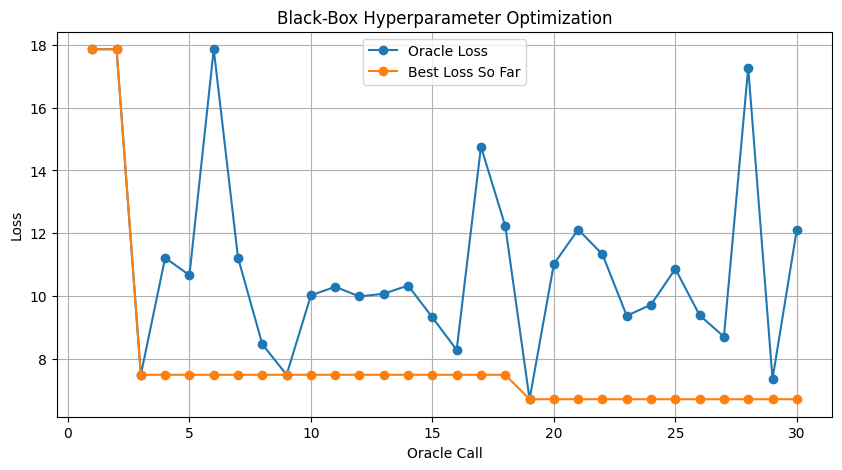

In [25]:
best_so_far = []
current_best = float("inf")

for loss in history_df["loss"]:

    current_best = min(current_best, loss)

    best_so_far.append(current_best)


plt.figure(figsize=(10, 5))

plt.plot(
    history_df["call"],
    history_df["loss"],
    marker="o",
    label="Oracle Loss"
)

plt.plot(
    history_df["call"],
    best_so_far,
    marker="o",
    label="Best Loss So Far"
)

plt.xlabel("Oracle Call")
plt.ylabel("Loss")
plt.title("Black-Box Hyperparameter Optimization")

plt.legend()
plt.grid(True)

plt.show()

## Final Conclusion

The black-box hyperparameter optimization was performed using a custom
search strategy without using automated hyperparameter optimization
libraries.

A total of 30 Oracle calls were made.

The best configuration found was:

- splitter = best
- criterion = friedman_mse
- max_depth = 6
- max_features = 1
- min_samples_leaf = 8
- min_samples_split = 20

The lowest loss observed during the search was 6.721072.

The optimization history and loss progression are shown above.